# SentinelX AI — S3 : baseline de prédiction du RUL

**NASA C-MAPSS FD001.** Objectif : établir une référence classique et honnête avant les modèles séquentiels.

| Groupe | Moteurs | Rôle |
|---|---|---|
| Entraînement | 80 moteurs du train | apprentissage et **tous les choix** par validation croisée par moteur (5 tours) |
| Validation | 20 moteurs du train | vérification **unique** du modèle choisi |
| Test NASA | 100 moteurs de `test_FD001.txt` | évaluation finale, `RUL_FD001.txt` lu une seule fois (section 8) |

Trois modèles sont comparés : **régression linéaire**, **Ridge** (régression linéaire régularisée) et **forêt aléatoire**.
Le notebook `01_eda_fd001.ipynb` doit avoir été exécuté avant.

## 1. Préparation, données et décisions de l'EDA

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

ROOT = Path(".") if Path("data/raw").exists() else Path("..")
sys.path.insert(0, str(ROOT.resolve()))
from ml.src.data import add_rul, last_cycle_per_engine, load_cmapss
from ml.src.evaluation import compute_metrics, engine_folds, evaluate_on_zone
from ml.src.features import add_history_features, history_feature_names
from ml.src.models import MODEL_NAMES, create_model, cross_validate, train_and_predict

RAW_DIR = ROOT / "data" / "raw"
EDA_DIR = ROOT / "artifacts" / "eda_fd001"
OUT_DIR = ROOT / "artifacts" / "baseline_fd001"
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 2)

N_START = 20     # début de vie = 20 premiers cycles (chaque moteur de test en a au moins 31)
LR, RIDGE, RF = MODEL_NAMES


def save(fig, name):
    fig.savefig(FIG_DIR / name, dpi=120, bbox_inches="tight")
    plt.show()

In [2]:
split = json.loads((EDA_DIR / "fd001_engine_split.json").read_text(encoding="utf-8"))
groups = json.loads((EDA_DIR / "fd001_feature_groups.json").read_text(encoding="utf-8"))
eda = json.loads((EDA_DIR / "eda_fd001_summary.json").read_text(encoding="utf-8"))

SENSORS = groups["selected_sensors"]
TRAIN_ENGINES, VALIDATION_ENGINES = split["train_engines"], split["validation_engines"]
WINDOW, EVAL_HORIZON = eda["history_window"], eda["evaluation_horizon"]

for name in ["train_FD001.txt", "test_FD001.txt"]:          # mêmes fichiers que l'EDA
    assert hashlib.sha256((RAW_DIR / name).read_bytes()).hexdigest() == eda["raw_files_sha256"][name]

train_df = add_rul(load_cmapss(RAW_DIR / "train_FD001.txt"))
print(len(SENSORS), "capteurs - historique", WINDOW, "cycles - zone d'évaluation RUL <=", EVAL_HORIZON)

14 capteurs - historique 30 cycles - zone d'évaluation RUL <= 127


## 2. Features d'historique (calcul causal)

Pour chacun des 14 capteurs, au cycle $t$ et avec les cycles $\le t$ **du même moteur** uniquement :

| Feature | Calcul | Constat de l'EDA |
|---|---|---|
| `_mean` | moyenne des 30 derniers cycles | mesures bruitées / quantifiées |
| `_slope` | pente de la droite ajustée sur les 30 derniers cycles | dégradation qui s'accélère |
| `_delta` | mesure − moyenne des 20 premiers cycles du moteur (moyenne des cycles vus avant le cycle 20) | niveau de départ propre à chaque moteur |

Soit **42 features**, comparées aux **14 mesures instantanées**. Fonctions : `ml/src/features.py`.

Exemple calculé à la main (fenêtre 3, début de vie 2) — capteur `100, 102, 101, 105, 108` → moyenne `100, 101, 101, 102.67, 104.67`, pente `0, 2, 0.5, 1.5, 3.5`, écart `0, 1, 0, 4, 7` :

In [3]:
toy = pd.DataFrame({"unit_id": 1, "cycle": [1, 2, 3, 4, 5], "sensor_x": [100, 102, 101, 105, 108]})
toy = add_history_features(toy, ["sensor_x"], window=3, n_start=2)
assert np.allclose(toy["sensor_x_mean"], [100, 101, 101, 308 / 3, 314 / 3])
assert np.allclose(toy["sensor_x_slope"], [0, 2, 0.5, 1.5, 3.5])
assert np.allclose(toy["sensor_x_delta"], [0, 1, 0, 4, 7])

train_feat = add_history_features(train_df, SENSORS, WINDOW, N_START)
INSTANT_FEATURES = SENSORS
HISTORY_FEATURES = history_feature_names(SENSORS)

# Contrôle anti-fuite sur un vrai moteur : falsifier le futur ne change pas les features du passé.
engine_2 = train_df[train_df["unit_id"] == 2]
falsified = engine_2.copy()
falsified.loc[falsified["cycle"] > 60, SENSORS] += 1000
before = add_history_features(engine_2, SENSORS, WINDOW, N_START)
after = add_history_features(falsified, SENSORS, WINDOW, N_START)
assert np.allclose(before.loc[before["cycle"] <= 60, HISTORY_FEATURES], after.loc[after["cycle"] <= 60, HISTORY_FEATURES])
print(len(HISTORY_FEATURES), "features d'historique - aucune dépendance au futur")

42 features d'historique - aucune dépendance au futur


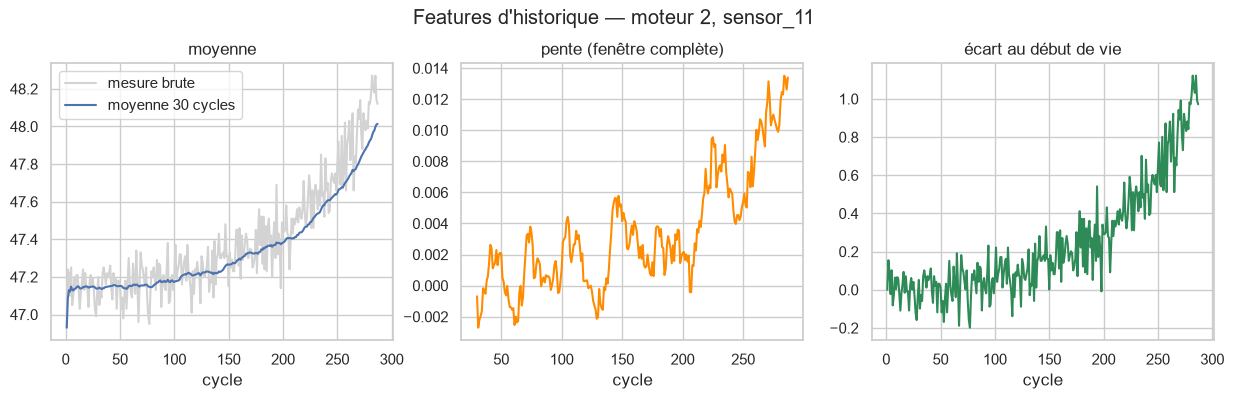

In [4]:
engine = train_feat[train_feat["unit_id"] == 2]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].plot(engine["cycle"], engine["sensor_11"], color="lightgray", label="mesure brute")
axes[0].plot(engine["cycle"], engine["sensor_11_mean"], label="moyenne 30 cycles")
axes[0].legend()
full = engine[engine["cycle"] >= WINDOW]
axes[1].plot(full["cycle"], full["sensor_11_slope"], color="darkorange")
axes[2].plot(engine["cycle"], engine["sensor_11_delta"], color="seagreen")
for ax, title in zip(axes, ["moyenne", "pente (fenêtre complète)", "écart au début de vie"]):
    ax.set(title=title, xlabel="cycle")
fig.suptitle("Features d'historique — moteur 2, sensor_11", y=1.03)
save(fig, "01_features_historique.png")

**Lecture.** La moyenne lisse le bruit, la pente reste proche de 0 en phase saine puis augmente avant la panne, et l'écart au début de vie croît avec la dégradation quel que soit le niveau de départ du moteur. Le code retrouve les valeurs calculées à la main et ne dépend pas du futur (vérifié aussi par `pytest`).

## 3. Protocole de comparaison

- **Validation croisée par moteur** : `GroupKFold(5)` répartit les 80 moteurs d'entraînement en 5 groupes de 16. À chaque tour, un modèle neuf apprend sur 64 moteurs et est contrôlé sur les 16 autres : aucun moteur n'est des deux côtés.
- **Métriques** : MAE, RMSE (en cycles) et R², calculés sur la zone utile **RUL réel ≤ 127**, toujours face au **vrai** RUL (jamais plafonné), ce qui rend les plafonds comparables. Le RMSE moyen des 5 tours est le critère ; son écart-type mesure la stabilité.
- **Règle de choix fixée à l'avance** : plus petit RMSE moyen. Les 20 moteurs de validation et le test n'interviennent dans aucun choix.

| Modèle | Réglage | Normalisation |
|---|---|---|
| Régression linéaire | aucun | inutile (prédictions invariantes à l'échelle) |
| Ridge | `alpha` (force de la pénalité) | `StandardScaler` dans un pipeline, appris sur les moteurs d'apprentissage de chaque tour |
| Forêt aléatoire | 100 arbres, `min_samples_leaf=5`, `max_features` | inutile (seuils sur chaque feature) |

In [5]:
train_part = train_feat[train_feat["unit_id"].isin(TRAIN_ENGINES)]
validation_feat = train_feat[train_feat["unit_id"].isin(VALIDATION_ENGINES)]
folds = engine_folds(train_part, n_splits=5)
for i, (fit_engines, check_engines) in enumerate(folds, 1):
    assert set(fit_engines).isdisjoint(check_engines) and not set(fit_engines) & set(VALIDATION_ENGINES)
    print(f"Tour {i} : {len(fit_engines)} moteurs pour apprendre, contrôle sur {check_engines}")


def run_experiment(options):
    # options : liste de (libellé, modèle, features, plafond, réglages). Renvoie un tableau de résultats.
    rows = []
    for label, model_name, features, cap, params in options:
        result = cross_validate(model_name, train_part, folds, features, cap, EVAL_HORIZON, **params)
        rows.append({"modèle": model_name, "option": label, **result})
    return pd.DataFrame(rows)

Tour 1 : 64 moteurs pour apprendre, contrôle sur [10, 17, 29, 30, 47, 51, 57, 59, 63, 66, 68, 69, 80, 90, 99, 100]
Tour 2 : 64 moteurs pour apprendre, contrôle sur [8, 12, 14, 21, 22, 39, 44, 53, 60, 76, 86, 88, 89, 92, 94, 97]
Tour 3 : 64 moteurs pour apprendre, contrôle sur [15, 20, 26, 28, 33, 37, 41, 48, 52, 55, 61, 64, 65, 70, 85, 96]
Tour 4 : 64 moteurs pour apprendre, contrôle sur [6, 7, 16, 24, 25, 35, 36, 38, 50, 67, 73, 79, 82, 87, 93, 95]
Tour 5 : 64 moteurs pour apprendre, contrôle sur [2, 3, 4, 9, 18, 27, 42, 43, 49, 56, 58, 62, 72, 75, 83, 98]


## 4. Expérience 1 — mesures instantanées ou historique ?

RUL plafonné à 125 (valeur illustrative de l'EDA) ; Ridge avec `alpha=1`. Le plafond est choisi à l'expérience 2.

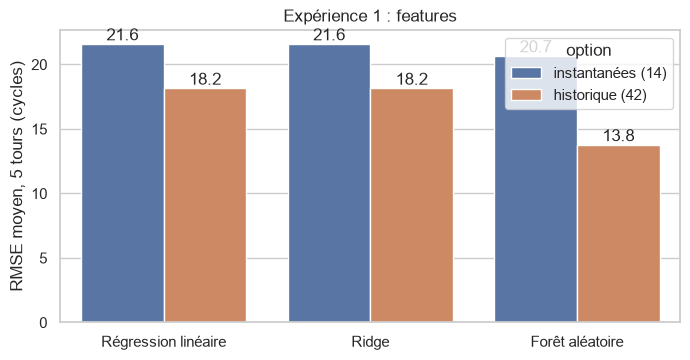

,modèle,option,RMSE,RMSE écart-type,MAE,R2
0,Régression linéaire,instantanées (14),21.60,2.63,17.65,0.65
1,Régression linéaire,historique (42),18.16,0.77,14.88,0.76
2,Ridge,instantanées (14),21.60,2.63,17.65,0.65
3,Ridge,historique (42),18.16,0.77,14.88,0.76
4,Forêt aléatoire,instantanées (14),20.68,3.08,15.25,0.68
5,Forêt aléatoire,historique (42),13.78,0.76,10.04,0.86


In [6]:
experiment_1 = run_experiment([(label, m, feats, 125, {}) for m in MODEL_NAMES
                               for label, feats in [("instantanées (14)", INSTANT_FEATURES), ("historique (42)", HISTORY_FEATURES)]])

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.barplot(data=experiment_1, x="modèle", y="RMSE", hue="option", ax=ax)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f")
ax.set(xlabel="", ylabel="RMSE moyen, 5 tours (cycles)", title="Expérience 1 : features")
save(fig, "02_choix_features.png")
experiment_1

**Résultats** (RMSE moyen, 5 tours, cycles) :

| | instantanées (14) | historique (42) |
|---|---|---|
| Régression linéaire | 21,6 | 18,2 |
| Ridge (`alpha=1`) | 21,6 | 18,2 |
| Forêt aléatoire | 20,7 | **13,8** |

**Interprétation.** L'historique améliore les trois modèles et rend les résultats plus stables (écart-type entre tours de 2,6–3,1 à moins de 0,8 cycle). La forêt en profite le plus : elle peut représenter la dégradation non linéaire « lente puis accélérée ». Avec `alpha=1`, Ridge est identique à la régression linéaire : avec plus de 13 000 lignes, une pénalité aussi faible est négligeable. **Les 42 features d'historique sont retenues.**

## 5. Expérience 2 — plafond du RUL

Avec les 42 features, on compare le RUL brut et les plafonds 100, 110, 125 et 140. Le plafond ne change que la **cible d'apprentissage** ; l'évaluation reste faite face au vrai RUL.

Plafond retenu : {'Régression linéaire': 110, 'Ridge': 110, 'Forêt aléatoire': 110}


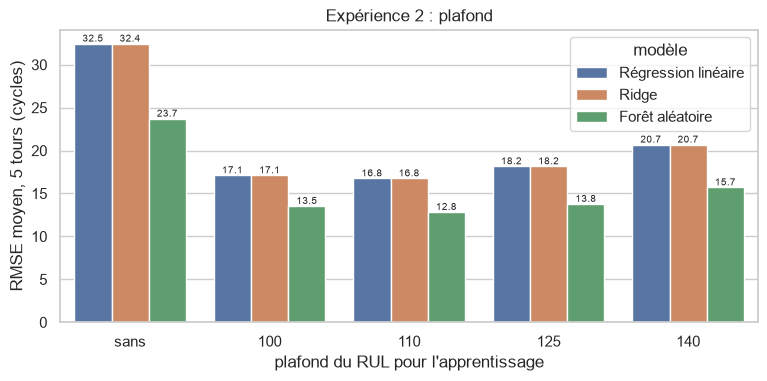

modèle,Régression linéaire,Ridge,Forêt aléatoire
option,,,
100,17.12,17.12,13.54
110,16.76,16.76,12.85
125,18.16,18.16,13.78
140,20.69,20.69,15.71
sans,32.45,32.45,23.71


In [7]:
CAPS = [None, 100, 110, 125, 140]
experiment_2 = run_experiment([("sans" if cap is None else cap, m, HISTORY_FEATURES, cap, {})
                               for m in MODEL_NAMES for cap in CAPS])

best_cap = {}
for model_name in MODEL_NAMES:
    rows = experiment_2[(experiment_2["modèle"] == model_name) & (experiment_2["option"] != "sans")]
    best_cap[model_name] = int(rows.sort_values("RMSE").iloc[0]["option"])
print("Plafond retenu :", best_cap)

fig, ax = plt.subplots(figsize=(9, 3.8))
sns.barplot(data=experiment_2.astype({"option": str}), x="option", y="RMSE", hue="modèle", ax=ax)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f", fontsize=7)
ax.set(xlabel="plafond du RUL pour l'apprentissage", ylabel="RMSE moyen, 5 tours (cycles)", title="Expérience 2 : plafond")
save(fig, "03_choix_plafond.png")
experiment_2.pivot(index="option", columns="modèle", values="RMSE")[MODEL_NAMES]

**Résultats** (RMSE moyen, 5 tours) : sans plafond, 32,5 (linéaire et Ridge) et 23,7 (forêt) ; avec plafond, le minimum est atteint à **110** pour les trois modèles (16,8 ; 16,8 ; **12,8**).

**Interprétation.** Plafonner est indispensable : sans plafond, le modèle s'épuise à prédire les grands RUL du début de vie, que les capteurs ne permettent pas de distinguer. Les écarts entre 100, 110 et 125 restent de l'ordre d'un cycle : 110 est un bon choix, pas une valeur exacte au cycle près. Choix fait uniquement sur les 80 moteurs d'entraînement.

## 6. Expérience 3 — un réglage par modèle régularisé

Deux vérifications courtes, avec le plafond retenu : `max_features` de la forêt (0,33 ou 1,0) et `alpha` de Ridge (1, 10, 100, 1000). Pas de recherche étendue : l'objectif est de valider des réglages classiques.

In [8]:
experiment_3 = run_experiment(
    [(mf, RF, HISTORY_FEATURES, best_cap[RF], {"max_features": mf}) for mf in [0.33, 1.0]]
    + [(a, RIDGE, HISTORY_FEATURES, best_cap[RIDGE], {"alpha": a}) for a in [1, 10, 100, 1000]])

best_params = {LR: {}}
cv_results = {LR: experiment_2[(experiment_2["modèle"] == LR) & (experiment_2["option"] == best_cap[LR])].iloc[0]}
for model_name, param in [(RF, "max_features"), (RIDGE, "alpha")]:
    best_row = experiment_3[experiment_3["modèle"] == model_name].sort_values("RMSE").iloc[0]
    best_params[model_name] = {param: float(best_row["option"])}
    cv_results[model_name] = best_row

cv_table = pd.DataFrame(cv_results).T.loc[MODEL_NAMES, ["RMSE", "RMSE écart-type", "MAE", "R2"]].astype(float)
SELECTED_MODEL = cv_table["RMSE"].idxmin()
print("Réglages retenus :", best_params)
print("Modèle retenu :", SELECTED_MODEL)
display(experiment_3)
cv_table

Réglages retenus : {'Régression linéaire': {}, 'Forêt aléatoire': {'max_features': 0.33}, 'Ridge': {'alpha': 1000.0}}
Modèle retenu : Forêt aléatoire


,modèle,option,RMSE,RMSE écart-type,MAE,R2
0,Forêt aléatoire,0.33,12.85,0.44,9.61,0.88
1,Forêt aléatoire,1.00,13.16,0.47,9.85,0.87
2,Ridge,1.00,16.76,0.38,13.80,0.79
3,Ridge,10.00,16.75,0.38,13.79,0.79
4,Ridge,100.00,16.69,0.41,13.76,0.80
5,Ridge,1000.00,16.63,0.48,13.72,0.80


,RMSE,RMSE écart-type,MAE,R2
Régression linéaire,16.76,0.38,13.80,0.79
Ridge,16.63,0.48,13.72,0.80
Forêt aléatoire,12.85,0.44,9.61,0.88


**Résultats.**
- Forêt : `max_features = 0,33` (12,85) fait mieux que 1,0 (13,16) → **0,33 retenu**, conformément à la règle habituelle.
- Ridge : le RMSE baisse à peine de `alpha = 1` (16,76) à `alpha = 1000` (16,63). `alpha = 1000` est retenu par la règle, mais le gain (0,13 cycle) est **inférieur à l'écart-type entre tours** (≈ 0,4) et se situe en bord de grille : il n'est pas significatif et la grille n'est volontairement pas étendue.

**Interprétation.** La redondance entre capteurs relevée dans l'EDA ne dégrade pas les prédictions linéaires : la régularisation n'apporte presque rien. La limite des modèles linéaires vient de la **non-linéarité** de la dégradation, pas de la colinéarité.

**Modèle retenu : forêt aléatoire** (RMSE moyen 12,8 en validation croisée, contre 16,8 et 16,6).

## 7. Vérification unique sur les 20 moteurs de validation

Chaque modèle, avec ses réglages figés, apprend sur les 80 moteurs d'entraînement et prédit les 20 moteurs de validation (jamais utilisés jusqu'ici).

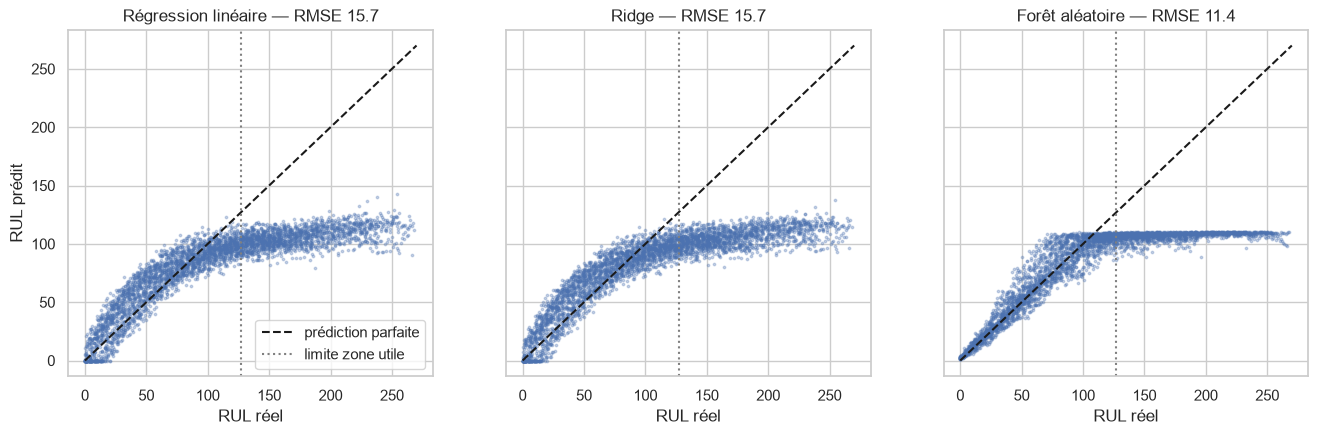

,MAE,RMSE,R2
Régression linéaire,12.89,15.72,0.82
Ridge,12.88,15.69,0.82
Forêt aléatoire,8.35,11.41,0.90


In [9]:
validation_results = validation_feat[["unit_id", "cycle", "RUL"]].copy()
validation_models, validation_metrics = {}, {}
for model_name in MODEL_NAMES:
    model, predictions = train_and_predict(model_name, train_part, validation_feat, HISTORY_FEATURES,
                                           best_cap[model_name], **best_params[model_name])
    validation_models[model_name] = model
    validation_results[model_name] = predictions
    validation_metrics[model_name] = evaluate_on_zone(validation_feat["RUL"], predictions, EVAL_HORIZON)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, model_name in zip(axes, MODEL_NAMES):
    ax.scatter(validation_results["RUL"], validation_results[model_name], s=3, alpha=0.3)
    ax.plot([0, 270], [0, 270], "k--", label="prédiction parfaite")
    ax.axvline(EVAL_HORIZON, color="gray", linestyle=":", label="limite zone utile")
    ax.set(xlabel="RUL réel", title=f"{model_name} — RMSE {validation_metrics[model_name]['RMSE']:.1f}")
axes[0].set_ylabel("RUL prédit")
axes[0].legend()
save(fig, "04_validation_pred_vs_reel.png")
pd.DataFrame(validation_metrics).T

**Erreur selon la distance à la panne.** Biais = moyenne de (prédit − réel). Un biais **positif** annonce plus de vie qu'il n'en reste : c'est la direction dangereuse pour la maintenance.

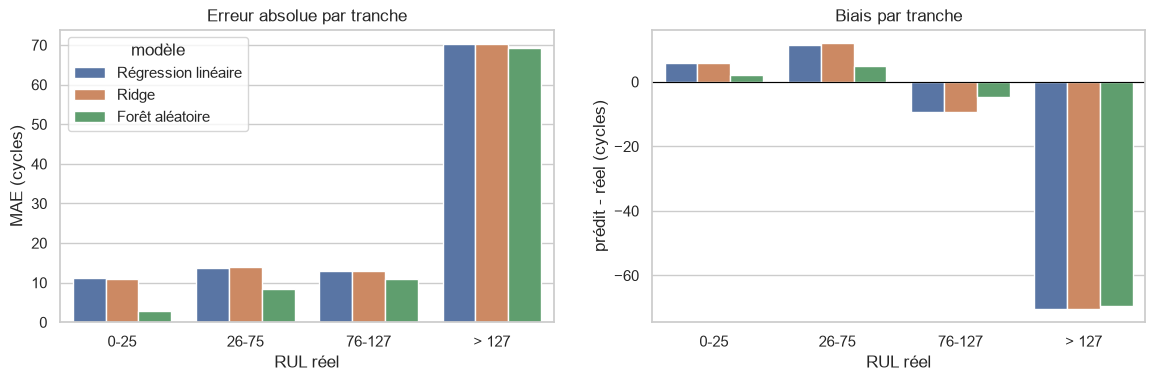

MAE                                     biais        \
modèle  Forêt aléatoire Ridge Régression linéaire Forêt aléatoire Ridge   
tranche                                                                   
0-25                2.8  11.0                11.1             2.0   5.8   
26-75               8.4  13.9                13.8             5.0  12.1   
76-127             11.0  12.9                12.9            -4.6  -9.3   
> 127              69.4  70.4                70.3           -69.4 -70.4   

                             
modèle  Régression linéaire  
tranche                      
0-25                    5.7  
26-75                  11.5  
76-127                 -9.3  
> 127                 -70.3

In [10]:
BANDS = ["0-25", "26-75", "76-127", "> 127"]
bands = pd.cut(validation_results["RUL"], bins=[-1, 25, 75, 127, 1000], labels=BANDS)
band_rows = []
for model_name in MODEL_NAMES:
    errors = validation_results[model_name] - validation_results["RUL"]
    for band in BANDS:
        band_rows.append({"modèle": model_name, "tranche": band,
                          "MAE": errors[bands == band].abs().mean(), "biais": errors[bands == band].mean()})
band_table = pd.DataFrame(band_rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
sns.barplot(data=band_table, x="tranche", y="MAE", hue="modèle", ax=axes[0])
sns.barplot(data=band_table, x="tranche", y="biais", hue="modèle", ax=axes[1], legend=False)
axes[0].set(xlabel="RUL réel", ylabel="MAE (cycles)", title="Erreur absolue par tranche")
axes[1].set(xlabel="RUL réel", ylabel="prédit - réel (cycles)", title="Biais par tranche")
axes[1].axhline(0, color="black", lw=0.8)
save(fig, "05_erreurs_par_tranche.png")
band_table.pivot(index="tranche", columns="modèle", values=["MAE", "biais"]).loc[BANDS].round(1)

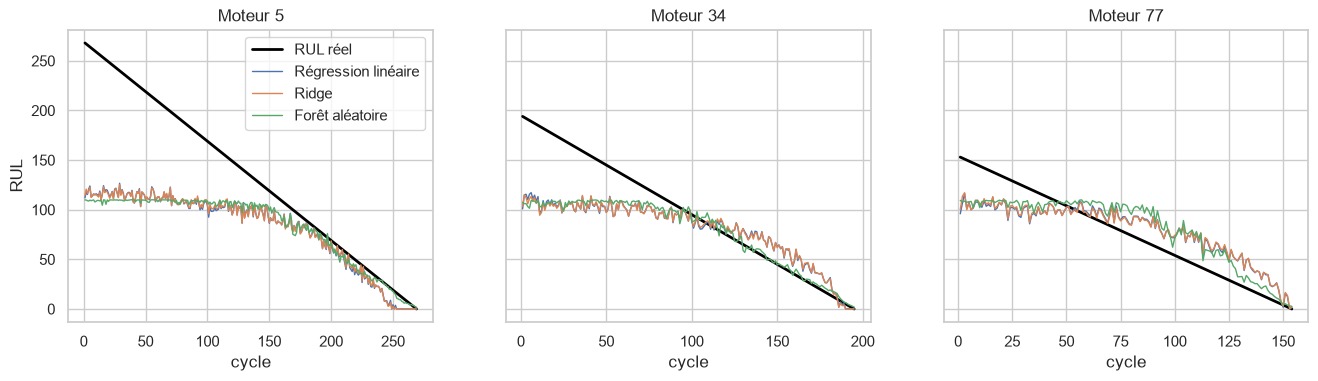

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for ax, engine_id in zip(axes, [5, 34, 77]):
    engine = validation_results[validation_results["unit_id"] == engine_id]
    ax.plot(engine["cycle"], engine["RUL"], color="black", lw=2, label="RUL réel")
    for model_name in MODEL_NAMES:
        ax.plot(engine["cycle"], engine[model_name], lw=1, label=model_name)
    ax.set(title=f"Moteur {engine_id}", xlabel="cycle")
axes[0].set_ylabel("RUL")
axes[0].legend()
save(fig, "06_trajectoires_validation.png")

**Résultats sur les 20 moteurs de validation** (zone RUL ≤ 127) : forêt **RMSE 11,4** (MAE 8,4, R² 0,90) ; régression linéaire 15,7 ; Ridge 15,7. Le classement de la validation croisée est confirmé.

| RUL réel | MAE forêt | MAE linéaire | MAE Ridge | Biais forêt |
|---|---|---|---|---|
| 0–25 (panne proche) | **2,8** | 11,1 | 11,0 | +2,0 |
| 26–75 | 8,4 | 13,8 | 13,9 | +5,0 |
| 76–127 | 11,0 | 12,9 | 12,9 | −4,6 |
| > 127 (moteur sain) | 69,4 | 70,3 | 70,4 | −69,4 |

**Interprétation.**
- La forêt est très précise près de la panne (2,8 cycles d'erreur moyenne), la zone la plus importante pour la maintenance.
- Entre 0 et 75 cycles, son biais est légèrement positif (+2 à +5 cycles) : elle annonce un peu trop de vie restante. Les modèles linéaires sont plus optimistes encore (+6 à +12). À prendre en compte pour les futurs seuils d'alerte.
- Au-delà de 127, la grande erreur négative est l'effet **voulu** du plafond : le modèle répond « au moins ~110 cycles ».
- Sur les trajectoires, les prédictions restent plates autour de 110 en phase saine puis suivent le RUL réel ; les courbes linéaires sont plus bruitées.

Importance par famille : {'_mean': 0.49, '_slope': 0.08, '_delta': 0.42}


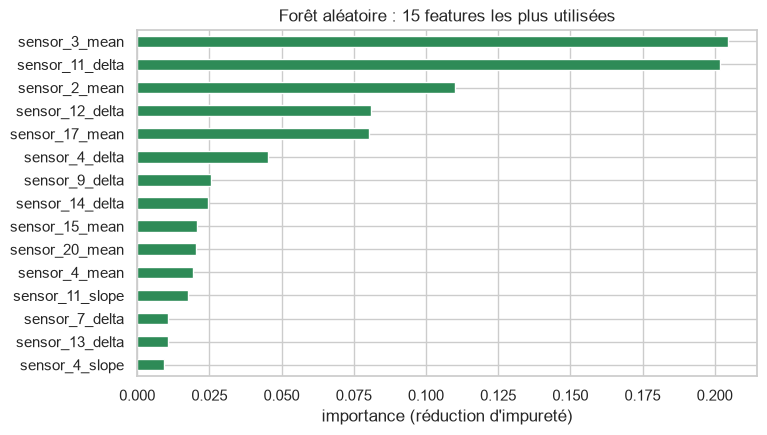

In [12]:
importances = pd.Series(validation_models[RF].feature_importances_, index=HISTORY_FEATURES).sort_values(ascending=False)
family_importance = {suffix: importances[[s + suffix for s in SENSORS]].sum() for suffix in ["_mean", "_slope", "_delta"]}
print("Importance par famille :", {k: round(float(v), 2) for k, v in family_importance.items()})

fig, ax = plt.subplots(figsize=(8, 4.5))
importances.head(15).iloc[::-1].plot.barh(ax=ax, color="seagreen")
ax.set(xlabel="importance (réduction d'impureté)", title="Forêt aléatoire : 15 features les plus utilisées")
save(fig, "07_importance_features.png")

**Interprétation.** La forêt s'appuie surtout sur les moyennes (49 % de l'importance) et les écarts au début de vie (42 %), peu sur les pentes (8 %) ; en tête : `sensor_3_mean` et `sensor_11_delta`. Cela rejoint les constats de l'EDA (bruit, niveau de départ propre à chaque moteur). L'importance indique ce que le modèle utilise, pas une cause physique de la panne ; elle se répartit arbitrairement entre features redondantes.

## 8. Modèles finaux et évaluation sur le test NASA

Les choix sont **figés**. Chaque modèle est réentraîné sur les 100 moteurs du train. Pour chaque moteur de test, les features sont calculées sur son historique observé et on prédit au **dernier cycle observé** (protocole NASA). `RUL_FD001.txt` est lu ici, une seule fois.

**Validation et test ne mesurent pas la même chose.** La validation évalue toutes les lignes de RUL ≤ 127 de moteurs suivis jusqu'à la panne ; le test évalue un seul point par moteur, avec des RUL réels pouvant dépasser le plafond. Les deux chiffres ne sont pas directement comparables.

**Limite d'indépendance du test.** Dans l'ancien projet, `RUL_FD001.txt` a déjà été lu par plusieurs versions de la baseline (RMSE 22,69 ; 14,23 ; 17,05 puis 14,4). Il n'a jamais servi directement à un choix (règle de validation croisée fixée à l'avance), mais connaître ces scores a pu orienter le travail, et les réglages repris ici en héritent. **Le score test est donc probablement un peu optimiste** ; les scores de validation croisée et des 20 moteurs de validation sont les références les plus propres.

In [13]:
full_train = train_feat
final_models = {}
for model_name in MODEL_NAMES:
    target = full_train["RUL"].clip(upper=best_cap[model_name])
    final_models[model_name] = create_model(model_name, **best_params[model_name]).fit(full_train[HISTORY_FEATURES], target)

test_last = last_cycle_per_engine(add_history_features(load_cmapss(RAW_DIR / "test_FD001.txt"), SENSORS, WINDOW, N_START))

true_test_rul = np.loadtxt(RAW_DIR / "RUL_FD001.txt")          # seule lecture de la vérité du test
assert len(true_test_rul) == len(test_last) and test_last["unit_id"].tolist() == list(range(1, 101))

test_results = test_last[["unit_id", "cycle"]].rename(columns={"cycle": "last_cycle"})
test_results["RUL_true"] = true_test_rul
test_metrics = {}
for model_name in MODEL_NAMES:
    test_results[model_name] = np.clip(final_models[model_name].predict(test_last[HISTORY_FEATURES]), 0, None)
    test_metrics[model_name] = compute_metrics(true_test_rul, test_results[model_name])
pd.DataFrame(test_metrics).T

,MAE,RMSE,R2
Régression linéaire,15.09,19.15,0.79
Ridge,15.19,19.18,0.79
Forêt aléatoire,10.53,14.40,0.88


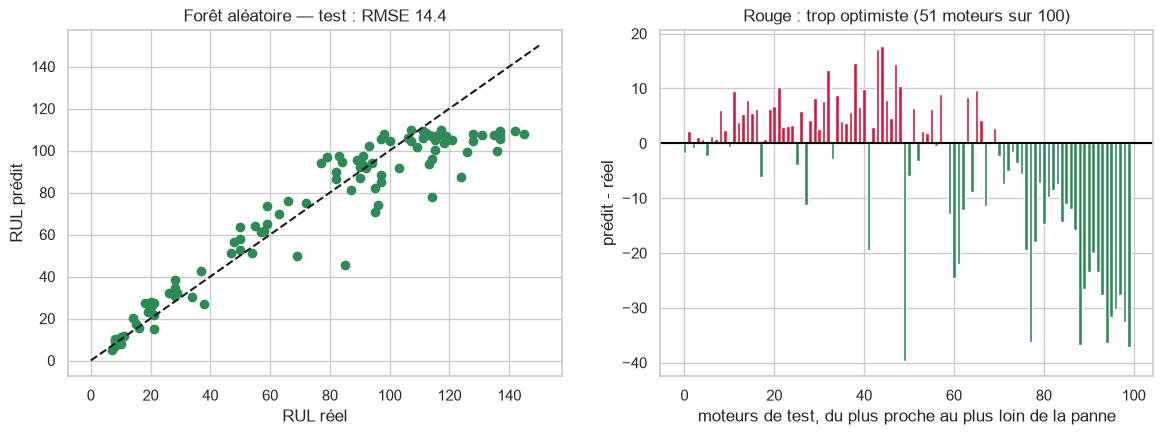

Plus grand dépassement : 17.8 cycles
RUL réel > plafond : 28 moteurs, erreur moyenne -19.4
Historique < 50 cycles : 7 moteurs, MAE 14.0 contre 10.3 pour les autres


In [14]:
errors = test_results[SELECTED_MODEL] - test_results["RUL_true"]
n_too_optimistic = int((errors > 0).sum())
healthy = test_results["RUL_true"] > best_cap[SELECTED_MODEL]
short = test_results["last_cycle"] < 50

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].scatter(test_results["RUL_true"], test_results[SELECTED_MODEL], color="seagreen")
axes[0].plot([0, 150], [0, 150], "k--")
axes[0].set(xlabel="RUL réel", ylabel="RUL prédit", title=f"{SELECTED_MODEL} — test : RMSE {test_metrics[SELECTED_MODEL]['RMSE']:.1f}")
ordered = errors.loc[test_results["RUL_true"].sort_values().index]
axes[1].bar(range(len(ordered)), ordered, color=np.where(ordered > 0, "crimson", "seagreen"))
axes[1].axhline(0, color="black")
axes[1].set(xlabel="moteurs de test, du plus proche au plus loin de la panne", ylabel="prédit - réel",
            title=f"Rouge : trop optimiste ({n_too_optimistic} moteurs sur 100)")
save(fig, "08_test_pred_vs_reel.png")

print("Plus grand dépassement :", round(float(errors.max()), 1), "cycles")
print("RUL réel > plafond :", int(healthy.sum()), "moteurs, erreur moyenne", round(float(errors[healthy].mean()), 1))
print("Historique < 50 cycles :", int(short.sum()), "moteurs, MAE", round(float(errors[short].abs().mean()), 1),
      "contre", round(float(errors[~short].abs().mean()), 1), "pour les autres")

**Résultats sur le test NASA** (100 moteurs, un point par moteur) :

| Modèle | MAE | RMSE | R² |
|---|---|---|---|
| Régression linéaire | 15,1 | 19,1 | 0,79 |
| Ridge | 15,2 | 19,2 | 0,79 |
| **Forêt aléatoire (retenue)** | **10,5** | **14,4** | **0,88** |

- Le classement est le même qu'en validation croisée et en validation.
- 51 moteurs sur 100 reçoivent une prédiction trop optimiste, au plus de 17,8 cycles.
- 28 moteurs ont un RUL réel supérieur au plafond (110) : ils sont sous-estimés de 19,4 cycles en moyenne, erreur prudente et voulue.
- Les 7 moteurs avec moins de 50 cycles d'historique ont une erreur moyenne de 14,0 cycles, contre 10,3 pour les autres.

Ces deux effets, et la différence de protocole (un point par moteur, RUL jusqu'à 145), expliquent que le RMSE test (14,4) soit supérieur à celui de la validation (11,4). Rappel : ce score test n'est pas totalement indépendant (section 8).

## 9. Sauvegarde des résultats

In [15]:
def rounded(metrics):
    return {name: round(float(value), 4) for name, value in metrics.items()}


bundle = {"model": final_models[SELECTED_MODEL], "model_name": SELECTED_MODEL, "features": HISTORY_FEATURES,
          "sensors": SENSORS, "window": WINDOW, "n_start": N_START, "rul_cap": best_cap[SELECTED_MODEL],
          "params": best_params[SELECTED_MODEL]}
joblib.dump(bundle, OUT_DIR / "baseline_rul_fd001.joblib")
reloaded = joblib.load(OUT_DIR / "baseline_rul_fd001.joblib")
assert np.allclose(reloaded["model"].predict(test_last[HISTORY_FEATURES]), final_models[SELECTED_MODEL].predict(test_last[HISTORY_FEATURES]))

baseline_metrics = {
    "dataset": "FD001", "sensors": SENSORS, "features": HISTORY_FEATURES,
    "window": WINDOW, "n_start": N_START, "evaluation_horizon": EVAL_HORIZON,
    "validation_engines": VALIDATION_ENGINES,
    "cross_validation": {"method": "GroupKFold(5) sur les 80 moteurs d'entraînement",
                         "fold_engines": [check for _, check in folds],
                         "metrics_zone": {m: rounded(cv_table.loc[m]) for m in MODEL_NAMES}},
    "rul_cap": best_cap, "params": best_params, "selected_model": SELECTED_MODEL,
    "random_forest_fixed_params": {"n_estimators": 100, "min_samples_leaf": 5, "random_state": 42},
    "validation_metrics_zone": {m: rounded(validation_metrics[m]) for m in MODEL_NAMES},
    "test_metrics_last_cycle": {m: rounded(test_metrics[m]) for m in MODEL_NAMES},
    "test_too_optimistic_selected_model": n_too_optimistic,
    "test_set_note": ("RUL_FD001.txt déjà lu par des versions précédentes (RMSE 22,69 ; 14,23 ; 17,05 ; 14,4) : "
                      "score test non totalement indépendant"),
    "versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
                 "scikit-learn": sklearn.__version__},
}
(OUT_DIR / "baseline_metrics.json").write_text(json.dumps(baseline_metrics, indent=2, ensure_ascii=False), encoding="utf-8")
test_results.round(4).to_csv(OUT_DIR / "test_predictions.csv", index=False)
print("Enregistré :", sorted(p.name for p in OUT_DIR.iterdir() if p.is_file()))

Enregistré : ['baseline_metrics.json', 'baseline_rul_fd001.joblib', 'test_predictions.csv']


## 10. Conclusion

| Modèle (plafond 110) | RMSE validation croisée (80 moteurs) | RMSE validation (20 moteurs) | RMSE test | MAE test | R² test |
|---|---|---|---|---|---|
| Régression linéaire | 16,8 | 15,7 | 19,1 | 15,1 | 0,79 |
| Ridge (`alpha=1000`) | 16,6 | 15,7 | 19,2 | 15,2 | 0,79 |
| **Forêt aléatoire (retenue)** | **12,8** | **11,4** | **14,4** | **10,5** | **0,88** |

**À retenir.**
1. L'historique récent (moyenne, pente, écart au début de vie) est la principale source de gain.
2. Le RUL plafonné à 110 cycles est le meilleur choix pour les trois modèles.
3. La régularisation Ridge n'apporte rien de significatif : la limite des modèles linéaires est la non-linéarité de la dégradation.
4. La forêt aléatoire est retenue ; elle est précise près de la panne mais légèrement optimiste.

**Limites.** Statistiques choisies à la main sur 30 cycles ; aucune distinction au-delà de 110 cycles ; pas d'intervalle de confiance ; données simulées ; 20 moteurs de validation ; score test non totalement indépendant.

**Référence pour les étapes suivantes** : mêmes 5 tours (`fold_engines` dans `baseline_metrics.json`), mêmes 20 moteurs de validation, même zone RUL ≤ 127, même protocole de test. Scores à battre : **12,8 / 11,4 / 14,4**.

La cellule suivante vérifie que les chiffres cités correspondent à l'exécution.

In [16]:
def rmse(table, model_name, option):
    return table[(table["modèle"] == model_name) & (table["option"] == option)]["RMSE"].iloc[0]


def band(model_name, name, column):
    return band_table[(band_table["modèle"] == model_name) & (band_table["tranche"] == name)][column].iloc[0]


checks = [  # (valeur calculée, valeur citée, décimales)
    (rmse(experiment_1, LR, "instantanées (14)"), 21.6, 1), (rmse(experiment_1, LR, "historique (42)"), 18.2, 1),
    (rmse(experiment_1, RIDGE, "historique (42)"), 18.2, 1), (rmse(experiment_1, RF, "instantanées (14)"), 20.7, 1),
    (rmse(experiment_1, RF, "historique (42)"), 13.8, 1),
    (rmse(experiment_2, LR, "sans"), 32.5, 1), (rmse(experiment_2, RF, "sans"), 23.7, 1),
    (rmse(experiment_2, LR, 110), 16.8, 1), (rmse(experiment_2, RF, 110), 12.8, 1),
    (rmse(experiment_3, RF, 0.33), 12.85, 2), (rmse(experiment_3, RF, 1.0), 13.16, 2),
    (rmse(experiment_3, RIDGE, 1), 16.76, 2), (rmse(experiment_3, RIDGE, 1000), 16.63, 2),
    (cv_table.loc[RIDGE, "RMSE"], 16.6, 1),
    (validation_metrics[RF]["RMSE"], 11.4, 1), (validation_metrics[RF]["MAE"], 8.4, 1), (validation_metrics[RF]["R2"], 0.90, 2),
    (validation_metrics[LR]["RMSE"], 15.7, 1), (validation_metrics[RIDGE]["RMSE"], 15.7, 1),
    (band(RF, "0-25", "MAE"), 2.8, 1), (band(LR, "0-25", "MAE"), 11.1, 1), (band(RIDGE, "0-25", "MAE"), 11.0, 1),
    (band(RF, "26-75", "MAE"), 8.4, 1), (band(RF, "76-127", "MAE"), 11.0, 1), (band(RF, "> 127", "MAE"), 69.4, 1),
    (band(RF, "0-25", "biais"), 2.0, 1), (band(RF, "26-75", "biais"), 5.0, 1), (band(RF, "76-127", "biais"), -4.6, 1),
    (family_importance["_mean"], 0.49, 2), (family_importance["_slope"], 0.08, 2), (family_importance["_delta"], 0.42, 2),
    (test_metrics[LR]["RMSE"], 19.1, 1), (test_metrics[RIDGE]["RMSE"], 19.2, 1), (test_metrics[RF]["RMSE"], 14.4, 1),
    (test_metrics[RF]["MAE"], 10.5, 1), (test_metrics[RF]["R2"], 0.88, 2), (test_metrics[RIDGE]["MAE"], 15.2, 1),
    (errors.max(), 17.8, 1), (errors[healthy].mean(), -19.4, 1),
    (errors[short].abs().mean(), 14.0, 1), (errors[~short].abs().mean(), 10.3, 1),
]
for i, (value, cited, digits) in enumerate(checks):
    assert round(float(value), digits) == cited, f"vérification {i} : {value} != {cited}"
assert best_cap == {LR: 110, RIDGE: 110, RF: 110} and SELECTED_MODEL == RF
assert best_params[RF] == {"max_features": 0.33} and best_params[RIDGE] == {"alpha": 1000.0}
assert list(importances.index[:2]) == ["sensor_3_mean", "sensor_11_delta"]
assert n_too_optimistic == 51 and healthy.sum() == 28 and short.sum() == 7
print(len(checks), "chiffres cités vérifiés.")

41 chiffres cités vérifiés.
